# Nuages de mots

## Imports et stopwords

In [1]:
from collections import Counter
from wordcloud import WordCloud
import os
import nltk
nltk.download('stopwords')
from nltk.corpus import stopwords
from IPython.display import Image

[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\gaeta\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping corpora\stopwords.zip.


In [ ]:
# Stopwords (Idem que dans s1)
sw = stopwords.words("french")
sw += ["les", "plus", "cette", "fait", "faire", "être", "deux", "comme", "dont", "tout",
       "ils", "bien", "sans", "peut", "tous", "après", "ainsi", "donc", "cet", "sous",
       "celle", "entre", "encore", "toutes", "pendant", "moins", "dire", "cela", "non",
       "faut", "trois", "aussi", "dit", "avoir", "doit", "contre", "depuis", "autres",
       "van", "het", "autre", "jusqu", "ville", "rossel", "dem", "brux", "louer", "app", "appart", "conf", "gar", "bain", "notaire", "comm", "int", "aven", "cond", "mod", "sal", "pièces", "mois", "ans", "année", "jours", "jour", "heures", "heure", "soir", "midi", "matin",
       "temps", "quart", "lundi", "mardi", "mercredi", "jeudi", "vendredi", "samedi", "dimanche", "janvier", "mars", "avril", "mai", "juin", "juillet", "août",
       "septembre", "octobre", "novembre", "décembre"]
sw = set(sw)


## Créer un fichier contenant le texte de tous les journaux d'une année donnée

In [3]:
# Choisir une année
year = 1933

In [5]:
# Lister les fichiers de cette année
data_path = '..'
txt_path = '../txt'
txts = [f for f in os.listdir(txt_path) if os.path.isfile(os.path.join(txt_path, f)) and str(year) in f]
len(txts)

100

In [6]:
# Stocker le contenu de ces fichiers dans une liste
content_list = []
for txt in txts:
    with open(os.path.join(txt_path, txt), 'r', encoding='utf-8') as f:
        content_list.append(f.read())

In [7]:
# Compter le nombre d'éléments (=fichiers) dans la liste
len(content_list)

100

In [8]:
# Imprimer les 200 premiers caractères du contenu du premier fichier
content_list[0][0:200]

"1er JANVIER *** LE SOIR — COLLISION ENTRE ATTELAGE ET AUTO. A Waerschoot; une violente collision •'est produite entre un attelage et l’auto d’une brasserie gantoise. Le conducteur du dernier véhicule,"

In [10]:
# Ecrire tout le contenu dans un fichier temporaire
temp_path = '../tmp'
if not os.path.exists(temp_path):
    os.mkdir(temp_path)
with open(os.path.join(temp_path, f'{year}.txt'), 'w', encoding='utf-8') as f:
    f.write(' '.join(content_list))

In [11]:
# Imprimer le contenu du fichier et constater les "déchets"
with open(os.path.join(temp_path, f'{year}.txt'), 'r', encoding='utf-8') as f:
    before = f.read()

before[:500]

"1er JANVIER *** LE SOIR — COLLISION ENTRE ATTELAGE ET AUTO. A Waerschoot; une violente collision •'est produite entre un attelage et l’auto d’une brasserie gantoise. Le conducteur du dernier véhicule, Arthur Engels, domicilié à Gand, fut sérieusement blessé à la tête et se plaint de douleurs internes. M. C. (P.) —LA RUCHE D’OR, 33, rue au Beurre. Pains d’épices au miel fin d’ancienne réputation. fourrés au melon confit. 29261 — FERMES INCENDIÉES. A Kieldrecht, un incendie, dont les causes sont i"

## Nettoyer le fichier à l'aide d'une fonction de nettoyage

### Créer la fonction de nettoyage (à adapter)

In [12]:
def clean_text(year, folder=None):
    if folder is None:
        input_path = f"{year}.txt"
        output_path = f"{year}_clean.txt"
    else:
        input_path = f"{folder}/{year}.txt"
        output_path = f"{folder}/{year}_clean.txt"
    output = open(output_path, "w", encoding='utf-8')
    with open(input_path, 'r', encoding='utf-8') as f:
        text = f.read()
        words = nltk.wordpunct_tokenize(text)
        kept = [w.upper() for w in words if len(w) > 2 and w.isalpha() and w.lower() not in sw]
        kept_string = " ".join(kept)
        output.write(kept_string)
    return f'Output has been written in {output_path}!'

### Appliquer la fonction sur le fichier complet de l'année

In [13]:
clean_text(year, folder=temp_path)

'Output has been written in ../tmp/1933_clean.txt!'

In [14]:
# Vérifier le résultat
with open(os.path.join(temp_path, f'{year}_clean.txt'), 'r', encoding='utf-8') as f:
    after = f.read()

after[:500]

'JANVIER SOIR COLLISION ATTELAGE AUTO WAERSCHOOT VIOLENTE COLLISION PRODUITE ATTELAGE AUTO BRASSERIE GANTOISE CONDUCTEUR DERNIER VÉHICULE ARTHUR ENGELS DOMICILIÉ GAND SÉRIEUSEMENT BLESSÉ TÊTE PLAINT DOULEURS INTERNES RUCHE RUE BEURRE PAINS ÉPICES MIEL FIN ANCIENNE RÉPUTATION FOURRÉS MELON CONFIT FERMES INCENDIÉES KIELDRECHT INCENDIE CAUSES INCONUES ÉCLATÉ CHEZ FERMIERS VERDICKT BLOCK BÂTIMENTS CONTIGUS GRANGES ÉTABLES MOISSON INSTRUMENTS ARATOIRES HUIT TÊTES BÉTAIL DÉTRUITS ENQUÊTE OUVERTE DÉGÂTS'

## Nuage de mots

### Afficher les termes les plus fréquents


In [15]:
frequencies = Counter(after.split())
print(frequencies.most_common(10))

[('RUE', 3501), ('BRUXELLES', 1460), ('PRIX', 1374), ('LOUER', 1120), ('MAISON', 1074), ('FRANCS', 805), ('TRÈS', 767), ('AGENCE', 746), ('HEURES', 741), ('TÉL', 718)]


### Créer, stocker et afficher le nuage de mots

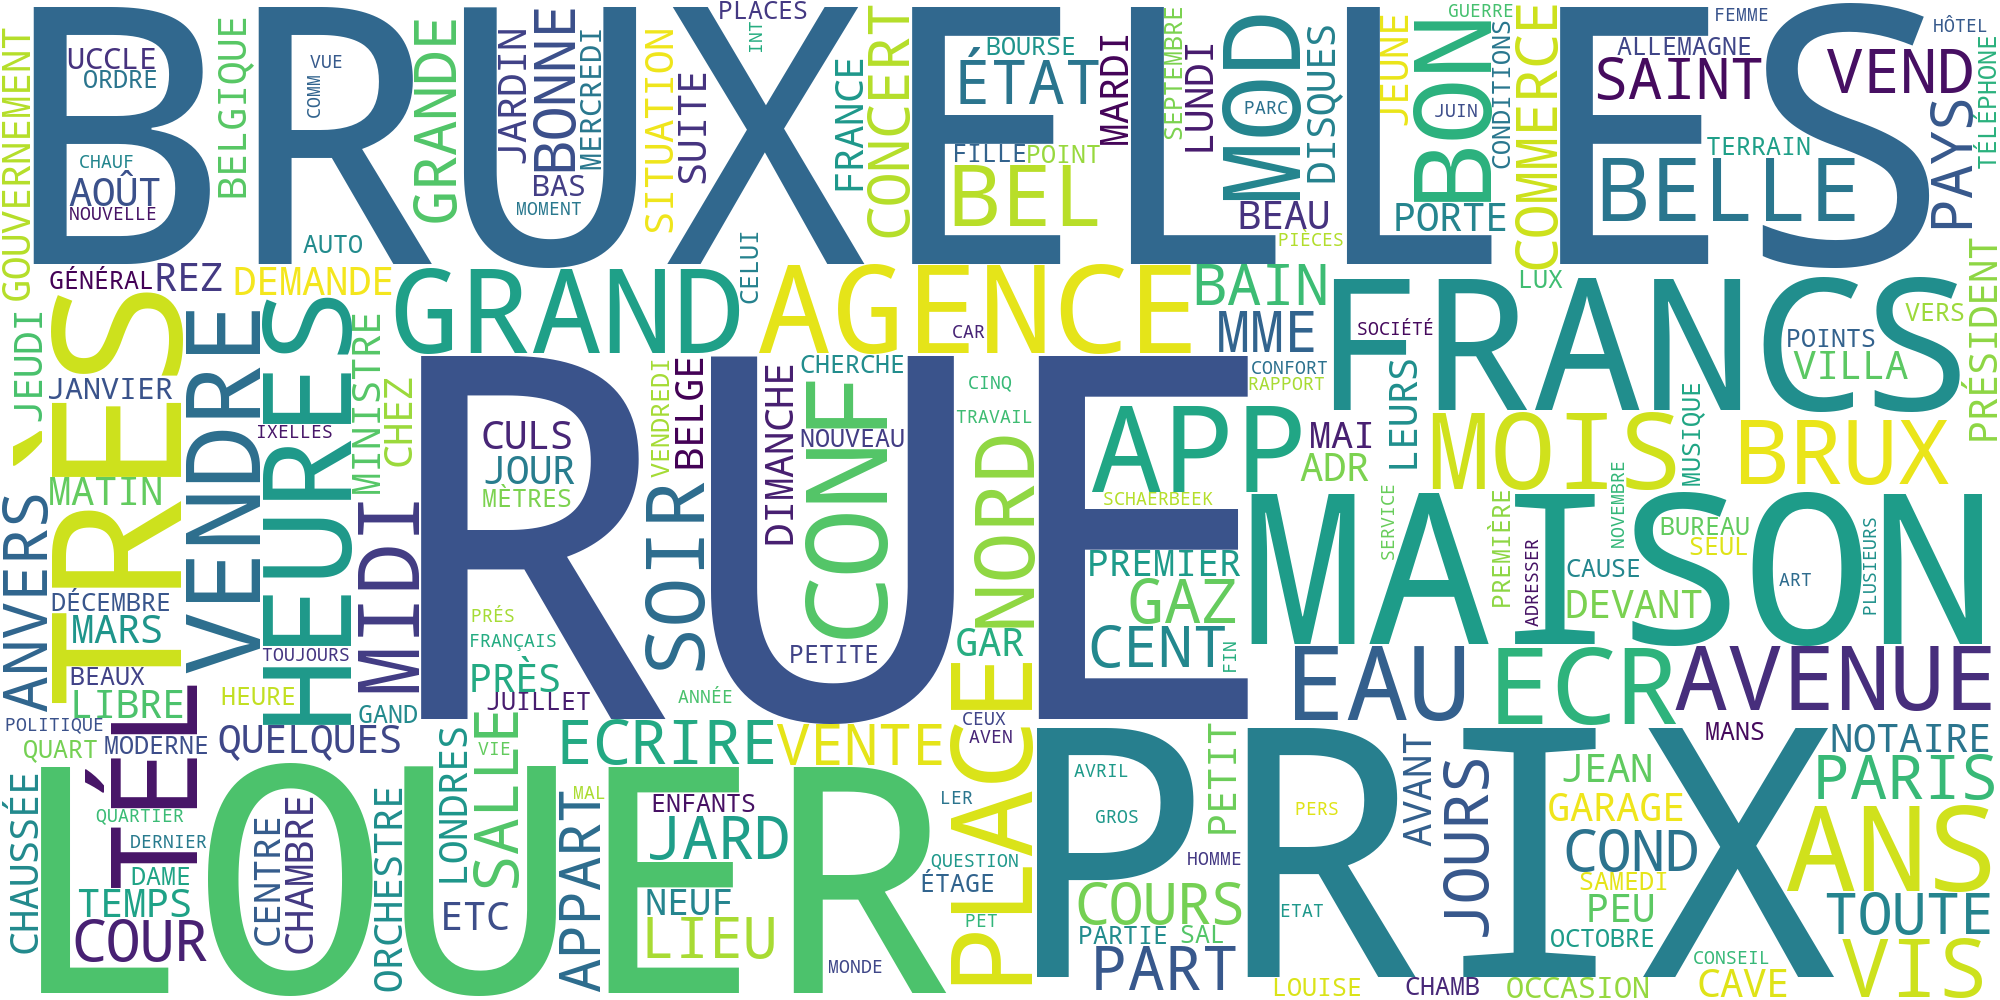

In [16]:
cloud = WordCloud(width=2000, height=1000, background_color='white').generate_from_frequencies(frequencies)
cloud.to_file(os.path.join(temp_path, f"{year}.png"))
Image(filename=os.path.join(temp_path, f"{year}.png"))